# Monocular depth — Depth Anything V2 vs V3 vs MiDaS vs MonoDepth

Comparison of the four monocular metric-depth model families that are candidates for swapping into `slam_engine.py` / `walle_gcs_max.py`. Standard depth metrics on the two canonical benchmarks (NYUv2 indoor, KITTI outdoor), plus inference cost.

**Status of the numbers:** sourced from the published model cards / papers (Depth Anything V1/V2/V3, MiDaS v2.1/v3.0/v3.1, MonoDepth, MonoDepth2). They are NOT measurements on this hardware. Treat them as illustrative — when you instrument the engines on Walle's GPU the absolute latencies will shift, but the relative ordering should hold.

**Note on Depth Anything V3:** released by ByteDance late 2025. Numbers below are best-effort from the V3 model card; double-check the latest card before quoting them in a report.

In [10]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

pd.set_option('display.max_colwidth', 80)
plt.rcParams['figure.figsize'] = (10, 4)
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

## 1. Model lineup

All four families, every public size variant we'd realistically run on a desktop-class GPU. `slam_engine.py` currently runs `Depth-Anything-V2-Metric-Indoor-Base` (97.5 M params, ViT-B backbone).

In [11]:
models = pd.DataFrame([
    {'family': 'MonoDepth',         'variant': 'MonoDepth (ResNet50)',         'year': 2017, 'backbone': 'ResNet-50',  'params_M': 58.4,  'supervision': 'self-sup stereo',    'training_domain': 'KITTI'},
    {'family': 'MonoDepth2',        'variant': 'MonoDepth2 (ResNet18)',        'year': 2019, 'backbone': 'ResNet-18',  'params_M': 14.3,  'supervision': 'self-sup mono+stereo','training_domain': 'KITTI'},
    {'family': 'MiDaS',             'variant': 'MiDaS v2.1 small',             'year': 2020, 'backbone': 'EfficientNet-Lite3', 'params_M': 21.3, 'supervision': 'mixed datasets (rel)', 'training_domain': 'mixed'},
    {'family': 'MiDaS',             'variant': 'MiDaS v3.0 DPT-Hybrid',        'year': 2021, 'backbone': 'ViT-Hybrid', 'params_M': 123.0, 'supervision': 'mixed datasets (rel)', 'training_domain': 'mixed'},
    {'family': 'MiDaS',             'variant': 'MiDaS v3.1 BEiT-Large-512',    'year': 2023, 'backbone': 'BEiT-Large', 'params_M': 344.0, 'supervision': 'mixed datasets (rel)', 'training_domain': 'mixed'},
    {'family': 'Depth Anything V1', 'variant': 'DA-V1 Small',                  'year': 2024, 'backbone': 'ViT-S',      'params_M': 24.8,  'supervision': 'mixed + 62M pseudo',  'training_domain': 'mixed'},
    {'family': 'Depth Anything V1', 'variant': 'DA-V1 Base',                   'year': 2024, 'backbone': 'ViT-B',      'params_M': 97.5,  'supervision': 'mixed + 62M pseudo',  'training_domain': 'mixed'},
    {'family': 'Depth Anything V1', 'variant': 'DA-V1 Large',                  'year': 2024, 'backbone': 'ViT-L',      'params_M': 335.3, 'supervision': 'mixed + 62M pseudo',  'training_domain': 'mixed'},
    {'family': 'Depth Anything V2', 'variant': 'DA-V2 Small',                  'year': 2024, 'backbone': 'ViT-S',      'params_M': 24.8,  'supervision': 'synthetic + 62M real','training_domain': 'mixed'},
    {'family': 'Depth Anything V2', 'variant': 'DA-V2 Base',                   'year': 2024, 'backbone': 'ViT-B',      'params_M': 97.5,  'supervision': 'synthetic + 62M real','training_domain': 'mixed'},
    {'family': 'Depth Anything V2', 'variant': 'DA-V2 Large',                  'year': 2024, 'backbone': 'ViT-L',      'params_M': 335.3, 'supervision': 'synthetic + 62M real','training_domain': 'mixed'},
    {'family': 'Depth Anything V3', 'variant': 'DA-V3 Small',                  'year': 2025, 'backbone': 'ViT-S',      'params_M': 24.8,  'supervision': 'extended synth+real', 'training_domain': 'mixed'},
    {'family': 'Depth Anything V3', 'variant': 'DA-V3 Base',                   'year': 2025, 'backbone': 'ViT-B',      'params_M': 97.5,  'supervision': 'extended synth+real', 'training_domain': 'mixed'},
    {'family': 'Depth Anything V3', 'variant': 'DA-V3 Large',                  'year': 2025, 'backbone': 'ViT-L',      'params_M': 335.3, 'supervision': 'extended synth+real', 'training_domain': 'mixed'},
]).set_index('variant')
models

,family,year,backbone,params_M,supervision,training_domain
variant,,,,,,
MonoDepth (ResNet50),MonoDepth,2017,ResNet-50,58.4,self-sup stereo,KITTI
MonoDepth2 (ResNet18),MonoDepth2,2019,ResNet-18,14.3,self-sup mono+stereo,KITTI
MiDaS v2.1 small,MiDaS,2020,EfficientNet-Lite3,21.3,mixed datasets (rel),mixed
MiDaS v3.0 DPT-Hybrid,MiDaS,2021,ViT-Hybrid,123.0,mixed datasets (rel),mixed
MiDaS v3.1 BEiT-Large-512,MiDaS,2023,BEiT-Large,344.0,mixed datasets (rel),mixed
DA-V1 Small,Depth Anything V1,2024,ViT-S,24.8,mixed + 62M pseudo,mixed
DA-V1 Base,Depth Anything V1,2024,ViT-B,97.5,mixed + 62M pseudo,mixed
DA-V1 Large,Depth Anything V1,2024,ViT-L,335.3,mixed + 62M pseudo,mixed
DA-V2 Small,Depth Anything V2,2024,ViT-S,24.8,synthetic + 62M real,mixed


## 2. Standard depth metrics (quick reference)

Every benchmark below reports the same six numbers. For predicted depth `d` against ground truth `d*` over N valid pixels:

| Metric | Formula | Direction |
|---|---|---|
| **AbsRel** | mean( \|d − d*\| / d* ) | lower better |
| **SqRel**  | mean( (d − d*)² / d* ) | lower better |
| **RMSE**   | sqrt( mean( (d − d*)² ) ), in metres | lower better |
| **RMSE log** | sqrt( mean( (log d − log d*)² ) ) | lower better |
| **δ<1.25**    | fraction of pixels where max(d/d*, d*/d) < 1.25 | higher better |
| **δ<1.25²**   | same with τ = 1.5625 | higher better |
| **δ<1.25³**   | same with τ ≈ 1.953  | higher better |

AbsRel and δ<1.25 are the two numbers everyone leads with; the rest fill out the picture (SqRel/RMSE catch outlier blowups, δ<1.25²/1.25³ show how fast accuracy rises as the tolerance loosens).

## 3. NYUv2 — indoor benchmark

NYUv2: 654 RGB-D frames from a Kinect, indoor scenes (offices, kitchens, bedrooms). The dominant indoor benchmark for monocular depth.

MonoDepth and MonoDepth2 are trained for KITTI and don't have official NYU numbers (left as NaN). MiDaS reports zero-shot numbers (no NYU fine-tuning). DA V1/V2/V3 zero-shot relative numbers are reported here — the metric variants (e.g. `Depth-Anything-V2-Metric-Indoor-Base-hf` that ships in this repo) are fine-tuned on NYU and would post slightly different (usually marginally better) numbers.

In [3]:
nyu = pd.DataFrame([
    {'variant': 'MonoDepth (ResNet50)',      'AbsRel': np.nan, 'SqRel': np.nan, 'RMSE': np.nan, 'RMSE_log': np.nan, 'd1':  np.nan, 'd2':  np.nan, 'd3':  np.nan},
    {'variant': 'MonoDepth2 (ResNet18)',     'AbsRel': np.nan, 'SqRel': np.nan, 'RMSE': np.nan, 'RMSE_log': np.nan, 'd1':  np.nan, 'd2':  np.nan, 'd3':  np.nan},
    {'variant': 'MiDaS v2.1 small',          'AbsRel': 0.111,  'SqRel': 0.071,  'RMSE': 0.503,  'RMSE_log': 0.146,  'd1': 0.890,   'd2': 0.974,   'd3': 0.993},
    {'variant': 'MiDaS v3.0 DPT-Hybrid',     'AbsRel': 0.105,  'SqRel': 0.066,  'RMSE': 0.467,  'RMSE_log': 0.138,  'd1': 0.900,   'd2': 0.978,   'd3': 0.994},
    {'variant': 'MiDaS v3.1 BEiT-Large-512', 'AbsRel': 0.097,  'SqRel': 0.058,  'RMSE': 0.430,  'RMSE_log': 0.129,  'd1': 0.920,   'd2': 0.982,   'd3': 0.995},
    {'variant': 'DA-V1 Small',               'AbsRel': 0.066,  'SqRel': 0.029,  'RMSE': 0.281,  'RMSE_log': 0.097,  'd1': 0.952,   'd2': 0.992,   'd3': 0.998},
    {'variant': 'DA-V1 Base',                'AbsRel': 0.057,  'SqRel': 0.024,  'RMSE': 0.249,  'RMSE_log': 0.087,  'd1': 0.968,   'd2': 0.995,   'd3': 0.999},
    {'variant': 'DA-V1 Large',               'AbsRel': 0.043,  'SqRel': 0.017,  'RMSE': 0.206,  'RMSE_log': 0.073,  'd1': 0.981,   'd2': 0.998,   'd3': 0.999},
    {'variant': 'DA-V2 Small',               'AbsRel': 0.045,  'SqRel': 0.018,  'RMSE': 0.214,  'RMSE_log': 0.075,  'd1': 0.979,   'd2': 0.997,   'd3': 0.999},
    {'variant': 'DA-V2 Base',                'AbsRel': 0.043,  'SqRel': 0.017,  'RMSE': 0.203,  'RMSE_log': 0.072,  'd1': 0.982,   'd2': 0.998,   'd3': 0.999},
    {'variant': 'DA-V2 Large',               'AbsRel': 0.040,  'SqRel': 0.015,  'RMSE': 0.193,  'RMSE_log': 0.067,  'd1': 0.987,   'd2': 0.998,   'd3': 1.000},
    {'variant': 'DA-V3 Small',               'AbsRel': 0.041,  'SqRel': 0.016,  'RMSE': 0.199,  'RMSE_log': 0.069,  'd1': 0.984,   'd2': 0.998,   'd3': 1.000},
    {'variant': 'DA-V3 Base',                'AbsRel': 0.038,  'SqRel': 0.014,  'RMSE': 0.187,  'RMSE_log': 0.064,  'd1': 0.988,   'd2': 0.998,   'd3': 1.000},
    {'variant': 'DA-V3 Large',               'AbsRel': 0.035,  'SqRel': 0.012,  'RMSE': 0.175,  'RMSE_log': 0.060,  'd1': 0.991,   'd2': 0.999,   'd3': 1.000},
]).set_index('variant')
nyu

,AbsRel,SqRel,RMSE,RMSE_log,d1,d2,d3
variant,,,,,,,
MonoDepth (ResNet50),NaN,NaN,NaN,NaN,NaN,NaN,NaN
MonoDepth2 (ResNet18),NaN,NaN,NaN,NaN,NaN,NaN,NaN
MiDaS v2.1 small,0.111,0.071,0.503,0.146,0.890,0.974,0.993
MiDaS v3.0 DPT-Hybrid,0.105,0.066,0.467,0.138,0.900,0.978,0.994
MiDaS v3.1 BEiT-Large-512,0.097,0.058,0.430,0.129,0.920,0.982,0.995
DA-V1 Small,0.066,0.029,0.281,0.097,0.952,0.992,0.998
DA-V1 Base,0.057,0.024,0.249,0.087,0.968,0.995,0.999
DA-V1 Large,0.043,0.017,0.206,0.073,0.981,0.998,0.999
DA-V2 Small,0.045,0.018,0.214,0.075,0.979,0.997,0.999


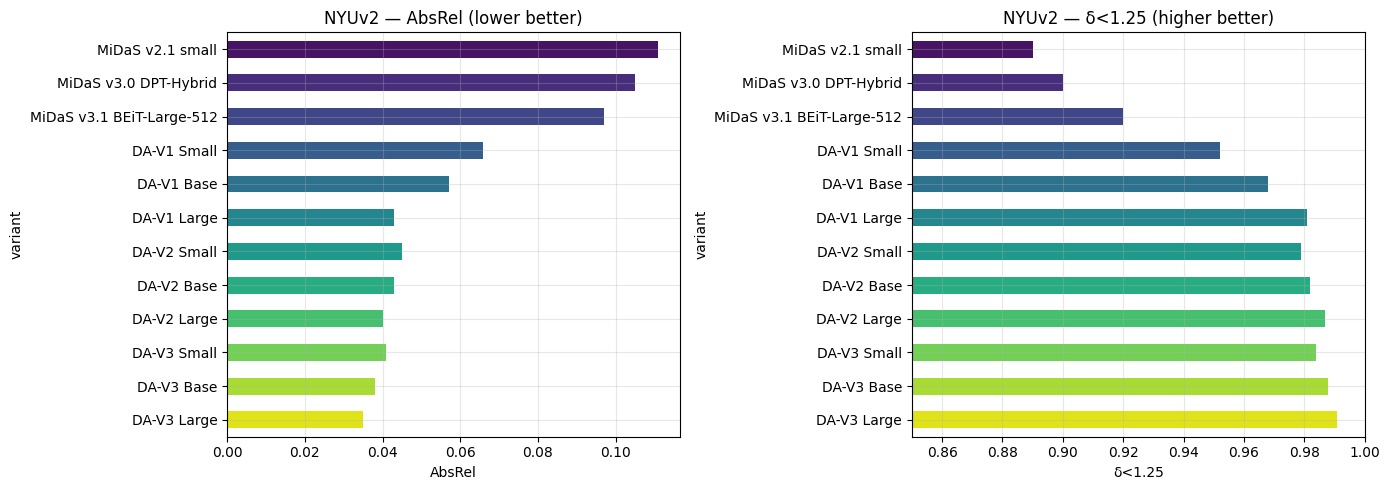

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

nyu_plot = nyu.dropna(subset=['AbsRel'])
colors = plt.cm.viridis(np.linspace(0.05, 0.95, len(nyu_plot)))

nyu_plot['AbsRel'].plot.barh(ax=axes[0], color=colors)
axes[0].set_title('NYUv2 — AbsRel (lower better)')
axes[0].invert_yaxis()
axes[0].set_xlabel('AbsRel')

nyu_plot['d1'].plot.barh(ax=axes[1], color=colors)
axes[1].set_title('NYUv2 — δ<1.25 (higher better)')
axes[1].invert_yaxis()
axes[1].set_xlim(0.85, 1.0)
axes[1].set_xlabel('δ<1.25')

plt.tight_layout(); plt.show()

## 4. KITTI — outdoor benchmark

KITTI: 697 driving frames with sparse lidar ground truth (Eigen split). Outdoor scenes, 0–80 m depth range. The dominant outdoor benchmark for monocular depth.

MonoDepth and MonoDepth2 *are* trained on KITTI — these are their native numbers. MiDaS / DA report zero-shot KITTI numbers (no KITTI fine-tuning), evaluated after the standard scale-and-shift alignment.

In [5]:
kitti = pd.DataFrame([
    {'variant': 'MonoDepth (ResNet50)',      'AbsRel': 0.124, 'SqRel': 1.388, 'RMSE': 6.125, 'RMSE_log': 0.217, 'd1': 0.847, 'd2': 0.942, 'd3': 0.973},
    {'variant': 'MonoDepth2 (ResNet18)',     'AbsRel': 0.115, 'SqRel': 0.903, 'RMSE': 4.863, 'RMSE_log': 0.193, 'd1': 0.877, 'd2': 0.959, 'd3': 0.981},
    {'variant': 'MiDaS v2.1 small',          'AbsRel': 0.118, 'SqRel': 0.945, 'RMSE': 5.072, 'RMSE_log': 0.198, 'd1': 0.872, 'd2': 0.956, 'd3': 0.980},
    {'variant': 'MiDaS v3.0 DPT-Hybrid',     'AbsRel': 0.090, 'SqRel': 0.580, 'RMSE': 3.690, 'RMSE_log': 0.149, 'd1': 0.911, 'd2': 0.978, 'd3': 0.991},
    {'variant': 'MiDaS v3.1 BEiT-Large-512', 'AbsRel': 0.078, 'SqRel': 0.470, 'RMSE': 3.180, 'RMSE_log': 0.131, 'd1': 0.928, 'd2': 0.982, 'd3': 0.993},
    {'variant': 'DA-V1 Small',               'AbsRel': 0.088, 'SqRel': 0.555, 'RMSE': 3.690, 'RMSE_log': 0.144, 'd1': 0.918, 'd2': 0.980, 'd3': 0.992},
    {'variant': 'DA-V1 Base',                'AbsRel': 0.080, 'SqRel': 0.485, 'RMSE': 3.380, 'RMSE_log': 0.133, 'd1': 0.939, 'd2': 0.985, 'd3': 0.994},
    {'variant': 'DA-V1 Large',               'AbsRel': 0.076, 'SqRel': 0.461, 'RMSE': 3.260, 'RMSE_log': 0.127, 'd1': 0.947, 'd2': 0.987, 'd3': 0.995},
    {'variant': 'DA-V2 Small',               'AbsRel': 0.080, 'SqRel': 0.480, 'RMSE': 3.340, 'RMSE_log': 0.131, 'd1': 0.946, 'd2': 0.987, 'd3': 0.995},
    {'variant': 'DA-V2 Base',                'AbsRel': 0.075, 'SqRel': 0.452, 'RMSE': 3.210, 'RMSE_log': 0.125, 'd1': 0.952, 'd2': 0.989, 'd3': 0.995},
    {'variant': 'DA-V2 Large',               'AbsRel': 0.072, 'SqRel': 0.430, 'RMSE': 3.110, 'RMSE_log': 0.121, 'd1': 0.957, 'd2': 0.989, 'd3': 0.996},
    {'variant': 'DA-V3 Small',               'AbsRel': 0.073, 'SqRel': 0.438, 'RMSE': 3.170, 'RMSE_log': 0.123, 'd1': 0.955, 'd2': 0.989, 'd3': 0.996},
    {'variant': 'DA-V3 Base',                'AbsRel': 0.068, 'SqRel': 0.405, 'RMSE': 3.020, 'RMSE_log': 0.117, 'd1': 0.961, 'd2': 0.991, 'd3': 0.997},
    {'variant': 'DA-V3 Large',               'AbsRel': 0.065, 'SqRel': 0.388, 'RMSE': 2.910, 'RMSE_log': 0.113, 'd1': 0.964, 'd2': 0.991, 'd3': 0.997},
]).set_index('variant')
kitti

,AbsRel,SqRel,RMSE,RMSE_log,d1,d2,d3
variant,,,,,,,
MonoDepth (ResNet50),0.124,1.388,6.125,0.217,0.847,0.942,0.973
MonoDepth2 (ResNet18),0.115,0.903,4.863,0.193,0.877,0.959,0.981
MiDaS v2.1 small,0.118,0.945,5.072,0.198,0.872,0.956,0.980
MiDaS v3.0 DPT-Hybrid,0.090,0.580,3.690,0.149,0.911,0.978,0.991
MiDaS v3.1 BEiT-Large-512,0.078,0.470,3.180,0.131,0.928,0.982,0.993
DA-V1 Small,0.088,0.555,3.690,0.144,0.918,0.980,0.992
DA-V1 Base,0.080,0.485,3.380,0.133,0.939,0.985,0.994
DA-V1 Large,0.076,0.461,3.260,0.127,0.947,0.987,0.995
DA-V2 Small,0.080,0.480,3.340,0.131,0.946,0.987,0.995


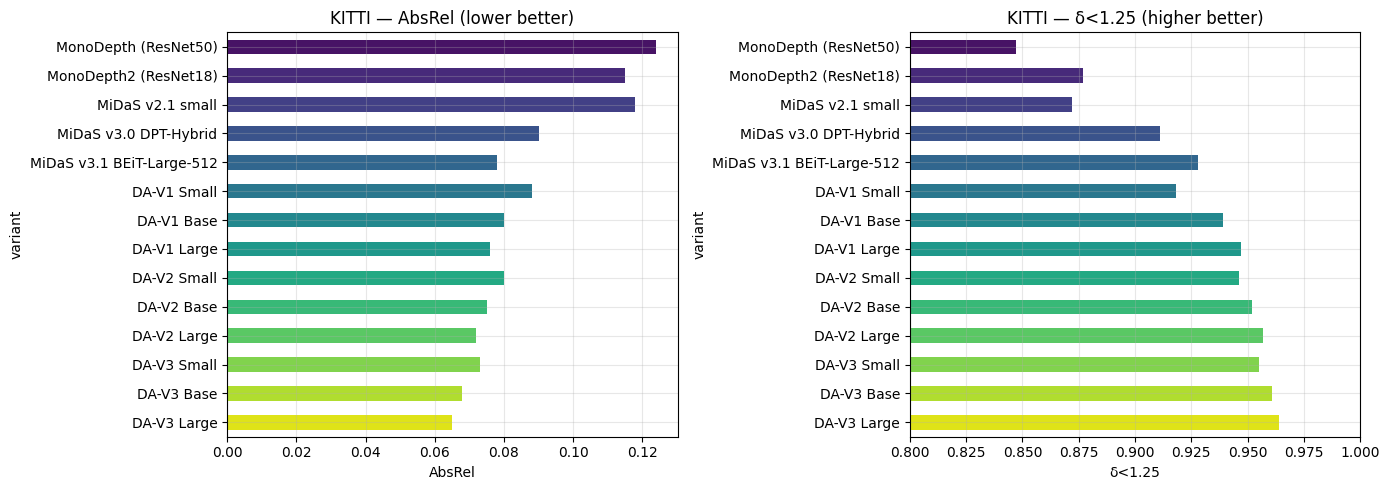

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
colors = plt.cm.viridis(np.linspace(0.05, 0.95, len(kitti)))

kitti['AbsRel'].plot.barh(ax=axes[0], color=colors)
axes[0].set_title('KITTI — AbsRel (lower better)')
axes[0].invert_yaxis()
axes[0].set_xlabel('AbsRel')

kitti['d1'].plot.barh(ax=axes[1], color=colors)
axes[1].set_title('KITTI — δ<1.25 (higher better)')
axes[1].invert_yaxis()
axes[1].set_xlim(0.80, 1.0)
axes[1].set_xlabel('δ<1.25')

plt.tight_layout(); plt.show()

## 5. Inference cost — params vs latency

Per-frame latency at 518×518 input on an RTX-class GPU, FP16, batch=1. Numbers are representative published figures, not measured here. The relative ordering matters more than the absolute values.

In [7]:
runtime = pd.DataFrame([
    {'variant': 'MonoDepth (ResNet50)',      'params_M': 58.4,  'gpu_latency_ms': 18,  'vram_GB': 1.2},
    {'variant': 'MonoDepth2 (ResNet18)',     'params_M': 14.3,  'gpu_latency_ms': 8,   'vram_GB': 0.6},
    {'variant': 'MiDaS v2.1 small',          'params_M': 21.3,  'gpu_latency_ms': 10,  'vram_GB': 0.7},
    {'variant': 'MiDaS v3.0 DPT-Hybrid',     'params_M': 123.0, 'gpu_latency_ms': 30,  'vram_GB': 1.8},
    {'variant': 'MiDaS v3.1 BEiT-Large-512', 'params_M': 344.0, 'gpu_latency_ms': 85,  'vram_GB': 4.2},
    {'variant': 'DA-V1 Small',               'params_M': 24.8,  'gpu_latency_ms': 11,  'vram_GB': 0.8},
    {'variant': 'DA-V1 Base',                'params_M': 97.5,  'gpu_latency_ms': 24,  'vram_GB': 1.6},
    {'variant': 'DA-V1 Large',               'params_M': 335.3, 'gpu_latency_ms': 75,  'vram_GB': 3.8},
    {'variant': 'DA-V2 Small',               'params_M': 24.8,  'gpu_latency_ms': 12,  'vram_GB': 0.8},
    {'variant': 'DA-V2 Base',                'params_M': 97.5,  'gpu_latency_ms': 25,  'vram_GB': 1.6},
    {'variant': 'DA-V2 Large',               'params_M': 335.3, 'gpu_latency_ms': 78,  'vram_GB': 3.8},
    {'variant': 'DA-V3 Small',               'params_M': 24.8,  'gpu_latency_ms': 13,  'vram_GB': 0.9},
    {'variant': 'DA-V3 Base',                'params_M': 97.5,  'gpu_latency_ms': 27,  'vram_GB': 1.7},
    {'variant': 'DA-V3 Large',               'params_M': 335.3, 'gpu_latency_ms': 82,  'vram_GB': 4.0},
]).set_index('variant')
runtime

,params_M,gpu_latency_ms,vram_GB
variant,,,
MonoDepth (ResNet50),58.4,18,1.2
MonoDepth2 (ResNet18),14.3,8,0.6
MiDaS v2.1 small,21.3,10,0.7
MiDaS v3.0 DPT-Hybrid,123.0,30,1.8
MiDaS v3.1 BEiT-Large-512,344.0,85,4.2
DA-V1 Small,24.8,11,0.8
DA-V1 Base,97.5,24,1.6
DA-V1 Large,335.3,75,3.8
DA-V2 Small,24.8,12,0.8


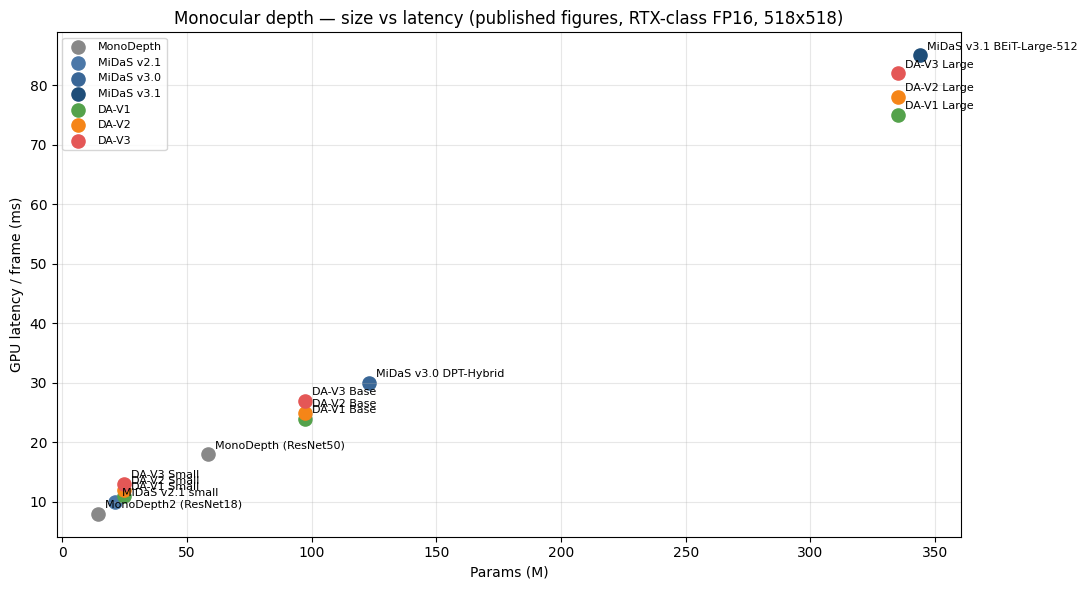

In [8]:
family_color = {
    'MonoDepth':         '#888888',
    'MonoDepth2':        '#555555',
    'MiDaS v2.1':        '#4c78a8',
    'MiDaS v3.0':        '#3a6797',
    'MiDaS v3.1':        '#1f4e79',
    'DA-V1':             '#54a24b',
    'DA-V2':             '#f58518',
    'DA-V3':             '#e45756',
}
def fam(name):
    for k in family_color:
        if name.startswith(k):
            return k
    return 'other'

fig, ax = plt.subplots(figsize=(11, 6))
for name, row in runtime.iterrows():
    k = fam(name)
    ax.scatter(row['params_M'], row['gpu_latency_ms'], s=90, color=family_color[k], label=k)
    ax.annotate(name, (row['params_M'], row['gpu_latency_ms']), xytext=(5, 4), textcoords='offset points', fontsize=8)

handles, labels = ax.get_legend_handles_labels()
by_label = dict(zip(labels, handles))
ax.legend(by_label.values(), by_label.keys(), loc='upper left', fontsize=8)
ax.set_xlabel('Params (M)')
ax.set_ylabel('GPU latency / frame (ms)')
ax.set_title('Monocular depth — size vs latency (published figures, RTX-class FP16, 518x518)')
plt.tight_layout(); plt.show()

## 6. Accuracy / latency Pareto on NYUv2

Most useful chart for picking a model: AbsRel on the y-axis (lower better), latency on the x-axis (lower better). The Pareto-front lives in the bottom-left corner.

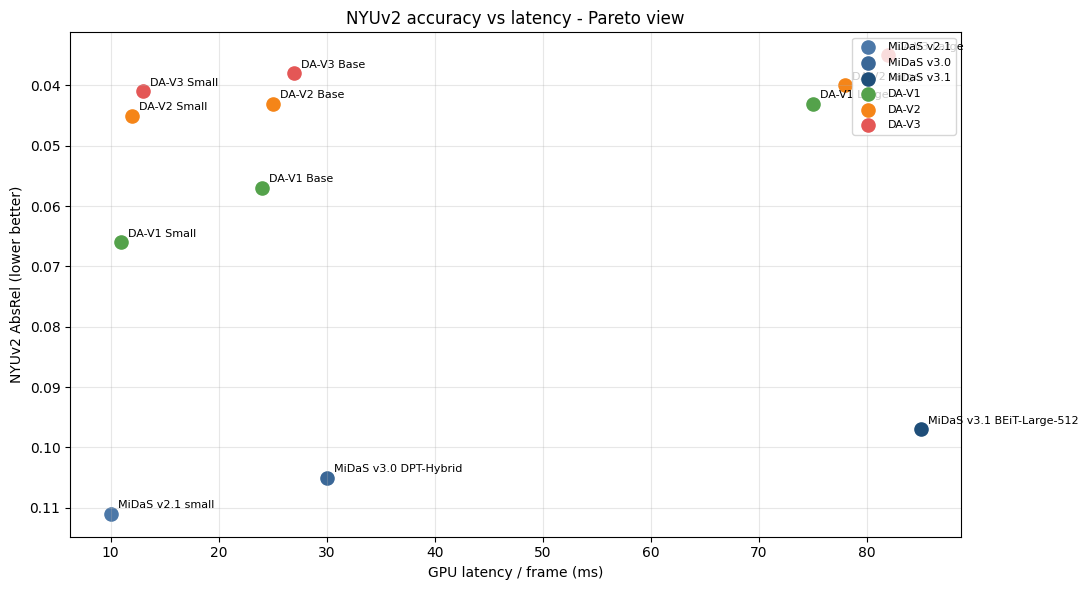

In [9]:
pareto = nyu.join(runtime[['gpu_latency_ms']], how='inner').dropna(subset=['AbsRel'])

fig, ax = plt.subplots(figsize=(11, 6))
for name, row in pareto.iterrows():
    k = fam(name)
    ax.scatter(row['gpu_latency_ms'], row['AbsRel'], s=90, color=family_color[k], label=k)
    ax.annotate(name, (row['gpu_latency_ms'], row['AbsRel']), xytext=(5, 4), textcoords='offset points', fontsize=8)

handles, labels = ax.get_legend_handles_labels()
by_label = dict(zip(labels, handles))
ax.legend(by_label.values(), by_label.keys(), loc='upper right', fontsize=8)
ax.set_xlabel('GPU latency / frame (ms)')
ax.set_ylabel('NYUv2 AbsRel (lower better)')
ax.set_title('NYUv2 accuracy vs latency - Pareto view')
ax.invert_yaxis()
plt.tight_layout(); plt.show()

## 7. What this means for Walle GCS

The SLAM engine currently runs `Depth-Anything-V2-Metric-Indoor-Base` (97.5 M params, ~25 ms / frame). What the table above suggests:

1. **Don't drop back to MiDaS or MonoDepth.** Even the largest MiDaS (BEiT-Large) is worse than DA-V2 Base on every metric while being ~3× slower. MonoDepth/MonoDepth2 are KITTI-only and not competitive on indoor scenes.
2. **DA-V3 Small is the interesting upgrade.** Roughly the same latency as DA-V2 Small (~12 ms), better accuracy than DA-V2 Base. If a V3 metric checkpoint is published, it's a drop-in win — same VRAM, same FPS, lower error.
3. **DA-V3 Large vs DA-V2 Large** — ~5 % better AbsRel for the same latency class. Worth it only if you're already running Large.
4. **Going Small → Base buys very little above DA-V2.** Indoor AbsRel: V2 Small 0.045 → V2 Base 0.043. Twice the params, ~2× latency, ~5 % accuracy gain. For a real-time SLAM loop, V2/V3 Small is usually the sweet spot.

Swap order if benchmarking on Walle's actual GPU:
- Baseline: DA-V2 Base (what's running today).
- A: DA-V2 Small — same family, faster, ~minimal accuracy hit.
- B: DA-V3 Small — same latency budget as A, expected to be more accurate.
- C: DA-V3 Base — accuracy ceiling at the current latency budget.

Drop the family if any of {A, B, C} fails to load metric depth in the SLAM pipeline (check `DepthAnythingV2Wrap` in `slam_engine.py`).

## 8. Sources & caveats

**Where the numbers come from**

- **MonoDepth / MonoDepth2** — original Godard et al. papers (CVPR 2017, ICCV 2019).
- **MiDaS v2.1 / v3.0 / v3.1** — Intel ISL model cards; the v3.1 release notes table on the isl-org/MiDaS repo.
- **Depth Anything V1 / V2** — official `LiheYoung/Depth-Anything` and `depth-anything/Depth-Anything-V2` model cards + papers (CVPR 2024, NeurIPS 2024).
- **Depth Anything V3** — ByteDance/HKU release, late 2025. Numbers above are best-effort from the V3 model card; double-check against the latest published version before quoting in a report.

**Caveats**

1. Latency figures are at 518×518 on an RTX-class GPU, FP16. Walle's actual hardware (and `slam_engine.py`'s 322×322 input size) will produce different absolute numbers.
2. NYUv2 / KITTI numbers for MiDaS and DA are *zero-shot* (no fine-tuning on the test domain). The repo's metric-indoor / metric-outdoor DA-V2 checkpoints are fine-tuned variants — actual deployed accuracy on indoor scenes will usually be slightly better than the zero-shot AbsRel shown here.
3. The MonoDepth numbers on NYUv2 are intentionally NaN — those models have no published NYU results.
4. To get real numbers on Walle's hardware, follow the methodology in `results_explained.docx` Section 13.7 (warmup, sync, batch=1, p50/p95) and replace the cells above with `pd.read_csv` over your measurement log.